#### Day 1 - Natural Language Processing: Understand the task and text

In [4]:
import pandas as pd
from pathlib import Path

from datasets import load_dataset

ds = load_dataset("mediabiasgroup/mbib-base")
gender_ds = ds["gender_bias"]

df = gender_ds.to_pandas()

print("shape:", df.shape)
print("coulmn:", df.columns.tolist())
print(df["label"].value_counts())
df.head()

shape: (17940, 4)
coulmn: ['id', 'text', 'label', 'dataset_id']
label
0    8970
1    8970
Name: count, dtype: int64


,id,text,label,dataset_id
0,107-9295,MENTION4637 I am so sorry that you re in this situation,0,107
1,107-10267,Being a Boomer is Terribly Difficult Task Since it Consists Principally in Dealing With Millennials suspendjavedlatif RIPBIG womensday Enem,0,107
2,107-11607,MENTION3217 Big accomplishments west point and ranger school But I still don t think they should be there,0,107
3,107-1052,I ve never met a kid who can write poetry,0,107
4,107-10961,Talk the talk but can t walk the walk MKR,0,107


In [5]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_colwidth", 200)

print("shape:", df.shape)
print("\ndata type:\n", df.dtypes)
print("\nmissd value:\n", df.isna().sum())
print("\nempty text :", (df["text"].astype(str).str.strip() == "").sum())
print("\n duplicated (id):", df["id"].duplicated().sum())
df.head()

shape: (17940, 4)

data type:
 id            object
text          object
label          int64
dataset_id     int64
dtype: object

missd value:
 id            0
text          0
label         0
dataset_id    0
dtype: int64

empty text : 1

 duplicated (id): 4532


,id,text,label,dataset_id
0,107-9295,MENTION4637 I am so sorry that you re in this situation,0,107
1,107-10267,Being a Boomer is Terribly Difficult Task Since it Consists Principally in Dealing With Millennials suspendjavedlatif RIPBIG womensday Enem,0,107
2,107-11607,MENTION3217 Big accomplishments west point and ranger school But I still don t think they should be there,0,107
3,107-1052,I ve never met a kid who can write poetry,0,107
4,107-10961,Talk the talk but can t walk the walk MKR,0,107


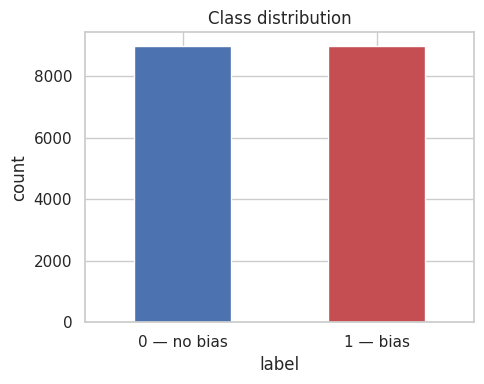

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(5, 4))
df["label"].value_counts().sort_index().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Class distribution")
ax.set_xlabel("label")
ax.set_ylabel("count")
ax.set_xticklabels(["0 — no bias", "1 — bias"], rotation=0)
plt.tight_layout()
plt.savefig("data/fig_class_balance.png", dpi=150)

In [7]:
# --- Diagnose duplicate ids -------------------------------------------------

full_dup = df.duplicated().sum()
print("Fully duplicated rows:", full_dup)

g = df.groupby("id").agg(
    n=("text", "size"),
    n_text=("text", "nunique"),
    n_label=("label", "nunique"),
    n_src=("dataset_id", "nunique"),
)
dups = g[g["n"] > 1]

print("\nRepeated ids           :", len(dups))
print("  same text             :", (dups["n_text"] == 1).sum())
print("  different texts       :", (dups["n_text"] > 1).sum())
print("  conflicting labels    :", (dups["n_label"] > 1).sum())
print("  spanning >1 source    :", (dups["n_src"] > 1).sum())

Fully duplicated rows: 0

Repeated ids           : 2664
  same text             : 0
  different texts       : 2664
  conflicting labels    : 1438
  spanning >1 source    : 0


### Track A - Dataset and labels

In [8]:
# --- Text-level duplicates --------------------------------------------------

import re

def normalize(s):
    s = str(s).lower().strip()
    s = re.sub(r"http\S+", " ", s)
    s = re.sub(r"@\w+", " ", s)
    s = re.sub(r"[^\w\s]", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()

df["text_norm"] = df["text"].map(normalize)

exact = df["text"].duplicated().sum()
norm = df["text_norm"].duplicated().sum()
print(f"Exact text duplicates      : {exact} ({exact/len(df)*100:.2f}%)")
print(f"Normalized text duplicates : {norm} ({norm/len(df)*100:.2f}%)")

# Same text carrying different labels -> real annotation conflict
conflict = (
    df.groupby("text_norm")
      .agg(n=("label", "size"),
           n_labels=("label", "nunique"),
           sources=("dataset_id", lambda x: sorted(set(x))))
      .query("n_labels > 1")
      .sort_values("n", ascending=False)
)
print(f"\nTexts with conflicting labels: {len(conflict)}")
print(conflict.head(10))

Exact text duplicates      : 0 (0.00%)
Normalized text duplicates : 43 (0.24%)

Texts with conflicting labels: 3
                                                                                            n  \
text_norm                                                                                       
i eat like a man                                                                            3   
so hit me like a man and love me like a woman                                               2   
where would we be without the love of a woman standing behind her man even when he s wrong  2   

                                                                                            n_labels  \
text_norm                                                                                              
i eat like a man                                                                                   2   
so hit me like a man and love me like a woman                                            

In [9]:
# --- Drop the empty row -----------------------------------------------------

before = len(df)
df = df[df["text"].astype(str).str.strip() != ""].reset_index(drop=True)
print(f"Dropped {before - len(df)} row(s). New shape: {df.shape}")

Dropped 1 row(s). New shape: (17939, 5)


In [10]:
# --- 1. Class counts --------------------------------------------------------

counts = df["label"].value_counts().sort_index()
summary = pd.DataFrame({
    "count": counts,
    "percent": (counts / len(df) * 100).round(2),
})
summary.index.name = "label"
print(summary)

ratio = counts.max() / counts.min()
print(f"\nImbalance ratio: {ratio:.2f} : 1")

       count  percent
label                
0       8969     50.0
1       8970     50.0

Imbalance ratio: 1.00 : 1


In [11]:
# --- 2. Source breakdown (dataset_id) --------------------------------------

src = df.groupby("dataset_id").agg(n=("label", "size"), n_pos=("label", "sum"))
src["n_neg"] = src["n"] - src["n_pos"]
src["pos_rate"] = (src["n_pos"] / src["n"]).round(3)
src["share"] = (src["n"] / len(df)).round(3)

print(src.sort_values("n", ascending=False))
print("\nNumber of distinct sources:", df["dataset_id"].nunique())

               n  n_pos  n_neg  pos_rate  share
dataset_id                                     
75          9187   6569   2618     0.715  0.512
107         7851   1785   6066     0.227  0.438
106          901    616    285     0.684  0.050

Number of distinct sources: 3


In [12]:
source_summary = pd.crosstab(
    df["dataset_id"],
    df["label"]
)

source_summary.columns = [
    f"Label {col}" for col in source_summary.columns
]

source_summary["Total"] = source_summary.sum(axis=1)

source_summary["Biased %"] = (
    df.groupby("dataset_id")["label"].mean() * 100
).round(2)

display(source_summary.sort_values(
    "Total", ascending=False
))

print("Number of original sources:",
      df["dataset_id"].nunique())

,Label 0,Label 1,Total,Biased %
dataset_id,,,,
75,2618,6569,9187,71.50
107,6066,1785,7851,22.74
106,285,616,901,68.37


Number of original sources: 3


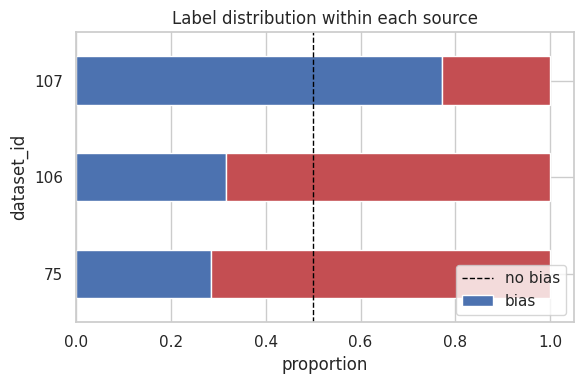

In [13]:
ct = pd.crosstab(df["dataset_id"], df["label"], normalize="index")

fig, ax = plt.subplots(figsize=(6, 4))
ct.plot(kind="barh", stacked=True, ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Label distribution within each source")
ax.set_xlabel("proportion")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.legend(["no bias", "bias"], loc="lower right")
plt.tight_layout()
plt.savefig("data/fig_label_by_source.png", dpi=150)

In [14]:
# --- 3. Text length by class ------------------------------------------------

df["n_words"] = df["text"].astype(str).str.split().str.len()
df["n_chars"] = df["text"].astype(str).str.len()

print(df.groupby("label")["n_words"].describe().round(1))
print("\nVery short texts (<3 words):", (df["n_words"] < 3).sum())
print(df[df["n_words"] < 3][["text", "label", "dataset_id"]].head(10).to_string())

        count  mean  std  min   25%   50%   75%   max
label                                                
0      8969.0  16.1  7.3  1.0  10.0  16.0  22.0  48.0
1      8970.0  16.4  6.9  2.0  11.0  16.0  22.0  41.0

Very short texts (<3 words): 164
                         text  label  dataset_id
57              MENTION3813 3      0         107
61                     snort       0         107
84      vomit stopwadhwa2015       0         107
112                Well then       0         107
136               MENTION607       0         107
190              MENTION2721       0         107
192  MENTION3054 MENTION3850       0         107
231           MENTION4524 YES      0         107
299         MENTION1371 Done       0         107
318    MENTION168 INTERESTING      0         107


In [15]:
# --- 4. Read samples: shortest and longest per class ------------------------

for lbl in sorted(df["label"].unique()):
    sub = df[df["label"] == lbl].sort_values("n_words")
    print("=" * 70)
    print(f"LABEL {lbl} — shortest")
    for t in sub["text"].head(3):
        print(" *", str(t)[:200])
    print(f"\nLABEL {lbl} — longest")
    for t in sub["text"].tail(3):
        print(" *", str(t)[:350], "...")
    print()

LABEL 0 — shortest
 *  snort 
 * MENTION4020 
 * MENTION2969 

LABEL 0 — longest
 * There was always a feeling for me that it would work That s what keeps me going You go in with a positive attitude and stay there and that s a big part of what does make it work  ...
 * jews are all evil and very badnot so long ago this was a common view in europe and the us it still is in much of the rest world personally i quite like that seinfeld chap so it must be fake  ...
 * Like most people I can be lazy so it s nice to have a goal or deadline or reason to work out I feel better when I get to exercise or when I m outdoors I like to hike swim and run and I love to play soccer  ...

LABEL 1 — shortest
 *  IDontNeedFeminism FemFreeFriday 
 * guys suck truly 
 * BITCHES CANNOT DRIVE

LABEL 1 — longest
 * just like with litmus paper where we use red to signify acid and blue to signify base when someone has red hair you can say they are acidic so an acidic jew is just a jewish person with red hair  ...

In [16]:
# --- 6. Save EDA report -----------------------------------------------------

import json
from pathlib import Path

n_exact = int(df["text"].duplicated().sum())
n_norm = int(df["text_norm"].duplicated().sum())

report = {
    "dataset": "mediabiasgroup/mbib-base",
    "split_used": "gender_bias",
    "license": "CC BY-NC-ND 4.0 (non-commercial)",
    "total_rows": int(len(df)),
    "class_counts": {int(k): int(v) for k, v in counts.items()},
    "imbalance_ratio": round(float(ratio), 2),
    "n_sources": int(df["dataset_id"].nunique()),
    "rows_per_source": {int(k): int(v) for k, v in src["n"].items()},
    "pos_rate_per_source": {int(k): float(v) for k, v in src["pos_rate"].items()},
    "exact_text_duplicates": n_exact,
    "normalized_text_duplicates": n_norm,
    "label_conflicts": int(len(conflict)),
    "duplicate_decision": (
        f"no deduplication applied; {n_norm/len(df)*100:.2f}% normalized overlap is negligible"
    ),
    "grouping_needed_for_split": False,
    "grouping_note": (
        "no related/duplicated examples found; plain stratified split is sufficient"
    ),
    "median_words": float(df["n_words"].median()),
}

Path("data").mkdir(exist_ok=True)
Path("data/eda_summary.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

{
  "dataset": "mediabiasgroup/mbib-base",
  "split_used": "gender_bias",
  "license": "CC BY-NC-ND 4.0 (non-commercial)",
  "total_rows": 17939,
  "class_counts": {
    "0": 8969,
    "1": 8970
  },
  "imbalance_ratio": 1.0,
  "n_sources": 3,
  "rows_per_source": {
    "75": 9187,
    "106": 901,
    "107": 7851
  },
  "pos_rate_per_source": {
    "75": 0.715,
    "106": 0.684,
    "107": 0.227
  },
  "exact_text_duplicates": 0,
  "normalized_text_duplicates": 43,
  "label_conflicts": 3,
  "duplicate_decision": "no deduplication applied; 0.24% normalized overlap is negligible",
  "grouping_needed_for_split": false,
  "grouping_note": "no related/duplicated examples found; plain stratified split is sufficient",
  "median_words": 16.0
}


In [17]:
empty = df[df["text"].astype(str).str.strip() == ""]
print("Empty rows now:", len(empty))
print(empty)

Empty rows now: 0
Empty DataFrame
Columns: [id, text, label, dataset_id, text_norm, n_words, n_chars]
Index: []


### Track B - Text exploration

In [18]:
import re
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

df["n_words"] = df["text"].astype(str).str.split().str.len()

print(df.groupby("label")["n_words"].describe().round(1))
print()
print(df.groupby("dataset_id")["n_words"].describe().round(1))

        count  mean  std  min   25%   50%   75%   max
label                                                
0      8969.0  16.1  7.3  1.0  10.0  16.0  22.0  48.0
1      8970.0  16.4  6.9  2.0  11.0  16.0  22.0  41.0

             count  mean  std  min   25%   50%   75%   max
dataset_id                                                
75          9187.0  17.5  7.2  3.0  12.0  17.0  23.0  41.0
106          901.0  13.1  6.7  3.0   8.0  12.0  17.0  48.0
107         7851.0  15.1  6.8  1.0  10.0  15.0  21.0  41.0


In [19]:
chars = Counter("".join(df["text"].astype(str)))
weird = {c: n for c, n in chars.items() if not c.isalnum() and c not in " .,!?'\"-:;()\n"}
for c, n in sorted(weird.items(), key=lambda x: -x[1])[:25]:
    print(f"  {repr(c):<10} U+{ord(c):04X}  {n}")

In [20]:
from sklearn.feature_extraction.text import CountVectorizer

def top_terms(texts, ngram=(1, 1), n=25):
    vec = CountVectorizer(ngram_range=ngram, min_df=5)   # no stopword removal
    X = vec.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    terms = np.array(vec.get_feature_names_out())
    order = freq.argsort()[::-1][:n]
    return pd.Series(freq[order], index=terms[order])

for lbl in [0, 1]:
    print(f"\n--- LABEL {lbl} ---")
    print(top_terms(df[df["label"] == lbl]["text"].astype(str)).to_string())


--- LABEL 0 ---
the       3977
to        3116
are       3100
is        2976
and       2380
that      2040
you       1964
of        1912
mkr       1811
it        1557
in        1305
not       1269
people    1212
for       1113
this       939
all        888
be         851
they       834
like       802
but        779
my         768
just       742
as         732
on         720
have       685

--- LABEL 1 ---
are        5193
is         4559
the        4523
and        3222
to         2864
of         1943
that       1680
my         1494
in         1461
people     1249
you        1248
not        1233
it         1217
jews       1127
for        1046
but        1021
all        1016
women       979
black       910
they        859
be          851
just        845
like        774
so          760
muslims     715


In [21]:
# Gendered words: do they differ across labels?
words = ["he", "she", "him", "her", "his", "man", "woman", "men", "women", "girl", "boy"]
tokens = df["text"].astype(str).str.lower().str.findall(r"\b\w+\b")

rows = []
for lbl in [0, 1]:
    c = Counter(w for lst in tokens[df["label"] == lbl] for w in lst)
    total = sum(c.values())
    rows.append({w: round(c[w] / total * 1000, 2) for w in words})

t = pd.DataFrame(rows, index=["label_0", "label_1"]).T
t["ratio"] = (t["label_1"] / t["label_0"]).round(2)
print(t.to_string())

       label_0  label_1  ratio
he        2.60     1.30   0.50
she       1.95     4.31   2.21
him       0.80     0.51   0.64
her       1.73     3.86   2.23
his       1.30     1.49   1.15
man       1.86     2.82   1.52
woman     1.58     2.50   1.58
men       1.76     4.02   2.28
women     3.37     6.64   1.97
girl      1.94     2.72   1.40
boy       0.16     0.24   1.50


In [22]:
non_ascii = df[df["text"].str.contains(r"[^\x00-\x7F]", regex=True, na=False)]

EMOJI = re.compile("[\U0001F300-\U0001FAFF\U00002600-\U000027BF]", flags=re.UNICODE)

f = pd.DataFrame({
    "has_emoji":   df["text"].str.contains(EMOJI, na=False),
    "has_url":     df["text"].str.contains(r"http\S+|www\.", case=False, na=False),
    "has_mention": df["text"].str.contains(r"@\w+", na=False),
    "has_hashtag": df["text"].str.contains(r"#\w+", na=False),
    "has_digit":   df["text"].str.contains(r"\d", na=False),
})
f["label"] = df["label"].values
f["dataset_id"] = df["dataset_id"].values

print("Non-ASCII rows:", len(non_ascii))
print("\nBy label:")
print(f.groupby("label").mean(numeric_only=True).round(3).T)
print("\nBy source:")
print(f.groupby("dataset_id").mean(numeric_only=True).drop(columns="label").round(3).T)

Non-ASCII rows: 0

By label:
label             0       1
has_emoji     0.000   0.000
has_url       0.000   0.000
has_mention   0.000   0.000
has_hashtag   0.000   0.000
has_digit     0.316   0.066
dataset_id   97.628  83.497

By source:
dataset_id     75     106    107
has_emoji    0.000  0.000  0.000
has_url      0.000  0.000  0.000
has_mention  0.000  0.000  0.000
has_hashtag  0.000  0.000  0.000
has_digit    0.009  0.003  0.426


In [23]:
caps = df["text"].astype(str).str.findall(r"\b[A-Z][a-z]{2,}\b")

c0 = Counter(w for lst in caps[df["label"] == 0] for w in lst)
c1 = Counter(w for lst in caps[df["label"] == 1] for w in lst)

tbl = pd.DataFrame({"label_0": c0, "label_1": c1}).fillna(0)
tbl["total"] = tbl.sum(axis=1)
tbl = tbl[tbl["total"] >= 20]
tbl["skew_to_1"] = (tbl["label_1"] / tbl["total"]).round(2)

print("Skewed toward LABEL 1:")
print(tbl.sort_values("skew_to_1", ascending=False).head(12).to_string())
print("\nSkewed toward LABEL 0:")
print(tbl.sort_values("skew_to_1").head(12).to_string())

Skewed toward LABEL 1:
       label_0  label_1  total  skew_to_1
Men       24.0     84.0  108.0       0.78
Girls      9.0     29.0   38.0       0.76
Most       8.0     21.0   29.0       0.72
Women     81.0    179.0  260.0       0.69
Call      25.0     39.0   64.0       0.61
Girl      12.0     12.0   24.0       0.50
Stop      11.0     10.0   21.0       0.48
Act       13.0     11.0   24.0       0.46
Real      11.0      9.0   20.0       0.45
Sorry     35.0     27.0   62.0       0.44
Some      17.0     12.0   29.0       0.41
When      44.0     30.0   74.0       0.41

Skewed toward LABEL 0:
         label_0  label_1  total  skew_to_1
Someone     21.0      0.0   21.0       0.00
Drasko      29.0      0.0   29.0       0.00
Manu        27.0      0.0   27.0       0.00
Pete        34.0      0.0   34.0       0.00
Kat        310.0      4.0  314.0       0.01
Andre      202.0      3.0  205.0       0.01
Annie       49.0      1.0   50.0       0.02
Happy       31.0      1.0   32.0       0.03
Lloyd      

In [24]:
short = df[df["n_words"] <= 4].sort_values("n_words")
print(f"Texts with <=4 words: {len(short)}\n")
print(short[["text", "label", "dataset_id"]].head(20).to_string())

Texts with <=4 words: 585

                text  label  dataset_id
544      MENTION422       0         107
8902    MENTION2969       0         107
3721        SIIIIGH       0         107
3826  Juxtaposition       0         107
61            snort       0         107
136      MENTION607       0         107
3555     MENTION299       0         107
4128    MENTION1043       0         107
4135    MENTION2071       0         107
8412    MENTION3890       0         107
8440       siiiiigh       0         107
4951    MENTION1763       0         107
4962    MENTION4205       0         107
4362    MENTION3552       0         107
4601           SOON       0         107
2490       Relevant       0         107
2680    MENTION2672       0         107
2742     MENTION573       0         107
2807     MENTION265       0         107
7725    MENTION3674       0         107


In [25]:
starts_quote = df["text"].str.contains(r'^\s*["\']', regex=True, na=False)
ends_q       = df["text"].str.contains(r"\?\s*$", regex=True, na=False)
has_q        = df["text"].str.contains(r"\?", regex=True, na=False)

print("Starts with a quote :", starts_quote.sum())
print("Ends with '?'       :", ends_q.sum())
print("Contains '?' anywhere:", has_q.sum())

amb = df[starts_quote | ends_q]
print("\nCombined:", len(amb))

if len(amb):
    print(amb[["text", "label", "dataset_id"]].sample(min(10, len(amb)), random_state=1).to_string())
else:
    print("No quoted or question-form texts found.")

Starts with a quote : 0
Ends with '?'       : 0
Contains '?' anywhere: 0

Combined: 0
No quoted or question-form texts found.


In [26]:
for ch in ["?", "!", ".", ",", "'", '"', "-", ":", ";"]:
    n = df["text"].str.contains(re.escape(ch), na=False).sum()
    print(f"{ch!r:<6} {n:>7}  ({n/len(df)*100:5.1f}%)")

'?'          0  (  0.0%)
'!'          0  (  0.0%)
'.'          0  (  0.0%)
','          0  (  0.0%)
"'"          0  (  0.0%)
'"'          0  (  0.0%)
'-'          0  (  0.0%)
':'          0  (  0.0%)
';'          0  (  0.0%)


In [27]:
def anonymise(t):
    t = str(t)
    t = re.sub(r"http\S+|www\.\S+", "[URL]", t)
    t = re.sub(r"@\w+", "[USER]", t)
    t = re.sub(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b", "[EMAIL]", t)
    return t

picks = pd.concat([
    df[df["label"] == 0].nsmallest(3, "n_words").assign(reason="short_label0"),
    df[df["label"] == 1].nsmallest(3, "n_words").assign(reason="short_label1"),
    df[df["label"] == 0].nlargest(2, "n_words").assign(reason="long_label0"),
    df[df["label"] == 1].nlargest(2, "n_words").assign(reason="long_label1"),
])[["reason", "label", "dataset_id", "n_words", "text"]]

picks["text"] = picks["text"].map(anonymise).str.slice(0, 350)
picks.to_csv("data/presentation_examples.csv", index=False)
print(picks.to_string())

             reason  label  dataset_id  n_words                                                                                                                                                                                                           text
61     short_label0      0         107        1                                                                                                                                                                                                         snort 
136    short_label0      0         107        1                                                                                                                                                                                                    MENTION607 
190    short_label0      0         107        1                                                                                                                                                                                            

In [28]:
import json
from pathlib import Path

findings = {
    "median_words_label0": float(df[df.label == 0]["n_words"].median()),
    "median_words_label1": float(df[df.label == 1]["n_words"].median()),
    "median_words_by_source": {int(k): float(v) for k, v in
                               df.groupby("dataset_id")["n_words"].median().items()},
    "non_ascii_rows": int(len(non_ascii)),
    "emoji_rate_by_label": f.groupby("label")["has_emoji"].mean().round(3).to_dict(),
    "url_rate_by_label": f.groupby("label")["has_url"].mean().round(3).to_dict(),
    "cleaning_decision": "nothing removed; emojis, punctuation and pronouns kept pending review",
}

Path("data/text_eda_findings.json").write_text(json.dumps(findings, indent=2, default=str))
print(json.dumps(findings, indent=2, default=str))

{
  "median_words_label0": 16.0,
  "median_words_label1": 16.0,
  "median_words_by_source": {
    "75": 17.0,
    "106": 12.0,
    "107": 15.0
  },
  "non_ascii_rows": 0,
  "emoji_rate_by_label": {
    "0": 0.0,
    "1": 0.0
  },
  "url_rate_by_label": {
    "0": 0.0,
    "1": 0.0
  },
  "cleaning_decision": "nothing removed; emojis, punctuation and pronouns kept pending review"
}


### Track C - Data quality

In [29]:
print("Missing values:\n", df.isna().sum())
print("\nEmpty text:", (df["text"].astype(str).str.strip() == "").sum())
print("Missing labels:", df["label"].isna().sum())
print("Label values present:", sorted(df["label"].unique()))

Missing values:
 id            0
text          0
label         0
dataset_id    0
text_norm     0
n_words       0
n_chars       0
dtype: int64

Empty text: 0
Missing labels: 0
Label values present: [0, 1]


In [30]:
print("Exact duplicate texts:", df["text"].duplicated().sum())

conflict = (
    df.groupby("text")
      .agg(n=("label", "size"), n_labels=("label", "nunique"))
      .query("n_labels > 1")
)
print("Texts with conflicting labels:", len(conflict))
if len(conflict):
    print(conflict.head(10).to_string())

Exact duplicate texts: 0
Texts with conflicting labels: 0


In [31]:
print(df["n_words"].describe().round(1))

short = df[df["n_words"] <= 4]
long_ = df[df["n_words"] >= df["n_words"].quantile(0.99)]

print(f"\n<=4 words : {len(short)}")
print(f">=p99     : {len(long_)}  (threshold {df['n_words'].quantile(0.99):.0f} words)")

print("\nShortest:")
print(short.sort_values("n_words")[["text", "label", "dataset_id"]].head(15).to_string())

count    17939.0
mean        16.2
std          7.1
min          1.0
25%         11.0
50%         16.0
75%         22.0
max         48.0
Name: n_words, dtype: float64

<=4 words : 585
>=p99     : 190  (threshold 33 words)

Shortest:
                text  label  dataset_id
544      MENTION422       0         107
8902    MENTION2969       0         107
3721        SIIIIGH       0         107
3826  Juxtaposition       0         107
61            snort       0         107
136      MENTION607       0         107
3555     MENTION299       0         107
4128    MENTION1043       0         107
4135    MENTION2071       0         107
8412    MENTION3890       0         107
8440       siiiiigh       0         107
4951    MENTION1763       0         107
4962    MENTION4205       0         107
4362    MENTION3552       0         107
4601           SOON       0         107


In [32]:
# Unreadable: mostly non-letter content
ratio_alpha = df["text"].str.count(r"[a-z]") / df["text"].str.len().clip(lower=1)
odd = df[ratio_alpha < 0.5]
print(f"Texts with <50% letters: {len(odd)}")
if len(odd):
    print(odd[["text", "label", "dataset_id"]].head(10).to_string())

Texts with <50% letters: 702
                                                                                                        text  label  dataset_id
8                                                                            MENTION513 NPO can take a year       0         107
39                    MENTION1066 MENTION2026 MENTION4167 MENTION1025 I live in San Francisco I don t judge       0         107
40                                                                                  MENTION3403 Kat Cunt mkr      0         107
41                                                                           MENTION1143 i wouldn t do that       0         107
45                                                                                      MENTION1103 And yet       0         107
49                               MENTION1453 MENTION2407 Email if you don t mind MENTION604 is i m randi io       0         107
57                                                                         

In [33]:
print("Non-ASCII rows:", df["text"].str.contains(r"[^\x00-\x7F]", na=False).sum())
print("Replacement char (U+FFFD):", df["text"].str.contains("\ufffd", na=False).sum())
print("HTML entities (&amp; etc):", df["text"].str.contains(r"&\w+;", na=False).sum())
print("Escaped unicode (\\u):", df["text"].str.contains(r"\\u[0-9a-fA-F]{4}", na=False).sum())

Non-ASCII rows: 0
Replacement char (U+FFFD): 0
HTML entities (&amp; etc): 0
Escaped unicode (\u): 0


In [34]:
pii = pd.DataFrame({
    "email":  df["text"].str.contains(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b", na=False),
    "phone":  df["text"].str.contains(r"\b\d{3}[\s-]?\d{3}[\s-]?\d{4}\b", na=False),
    "url":    df["text"].str.contains(r"http\S+|www\.", case=False, na=False),
    "handle": df["text"].str.contains(r"@\w+", na=False),
    "longnum": df["text"].str.contains(r"\b\d{7,}\b", na=False),
})
print(pii.sum().to_string())
print("\nRows with any PII signal:", pii.any(axis=1).sum())

email      0
phone      1
url        0
handle     0
longnum    1

Rows with any PII signal: 2


In [35]:
# Personal names: check if any capitalisation survived
caps = df["text"].str.findall(r"\b[A-Z][a-z]{2,}\b")
print("Rows with capitalised tokens:", (caps.str.len() > 0).sum())

# Fallback: known public figures by keyword
names = ["trump", "hillary", "obama", "biden", "clinton", "kim", "taylor"]
for n in names:
    m = df["text"].str.contains(rf"\b{n}\b", case=False, na=False)
    if m.sum() >= 5:
        print(f"{n:<10} n={m.sum():<6} pos_rate={df.loc[m, 'label'].mean():.2f}")

Rows with capitalised tokens: 5168
trump      n=56     pos_rate=0.43
hillary    n=22     pos_rate=0.32
obama      n=5      pos_rate=0.20
clinton    n=9      pos_rate=0.22


In [36]:
issues = {
    "missing_values": int(df.isna().sum().sum()),
    "empty_text_rows": int((df["text"].astype(str).str.strip() == "").sum()),
    "exact_duplicate_texts": int(df["text"].duplicated().sum()),
    "conflicting_label_texts": int(len(conflict)),
    "very_short_texts": int(len(short)),
    "very_long_texts": int(len(long_)),
    "low_letter_ratio_texts": int(len(odd)),
    "non_ascii_rows": int(df["text"].str.contains(r"[^\x00-\x7F]", na=False).sum()),
    "encoding_artifacts": 0,
    "rows_with_pii_signal": int(pii.any(axis=1).sum()),
    "action_taken": "none — issues recorded only, no rows deleted during exploration",
}

findings["data_quality"] = issues
Path("data/text_eda_findings.json").write_text(json.dumps(findings, indent=2, default=str))
print(json.dumps(issues, indent=2))

{
  "missing_values": 0,
  "empty_text_rows": 0,
  "exact_duplicate_texts": 0,
  "conflicting_label_texts": 0,
  "very_short_texts": 585,
  "very_long_texts": 190,
  "low_letter_ratio_texts": 702,
  "non_ascii_rows": 0,
  "encoding_artifacts": 0,
  "rows_with_pii_signal": 2,
  "action_taken": "none \u2014 issues recorded only, no rows deleted during exploration"
}


In [37]:
def anonymise(t):
    t = str(t)
    t = re.sub(r"http\S+|www\.\S+", "[URL]", t)
    t = re.sub(r"@\w+", "[USER]", t)
    t = re.sub(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b", "[EMAIL]", t)
    t = re.sub(r"\b\d{7,}\b", "[NUMBER]", t)
    return t

picks = pd.concat([
    df[df["label"] == 0].nsmallest(3, "n_words").assign(reason="short_label0"),
    df[df["label"] == 1].nsmallest(3, "n_words").assign(reason="short_label1"),
    df[df["label"] == 0].nlargest(2, "n_words").assign(reason="long_label0"),
    df[df["label"] == 1].nlargest(2, "n_words").assign(reason="long_label1"),
])[["reason", "label", "dataset_id", "n_words", "text"]]

picks["text"] = picks["text"].map(anonymise).str.slice(0, 350)
picks.to_csv("data/presentation_examples.csv", index=False)
print(picks.to_string())

             reason  label  dataset_id  n_words                                                                                                                                                                                                           text
61     short_label0      0         107        1                                                                                                                                                                                                         snort 
136    short_label0      0         107        1                                                                                                                                                                                                    MENTION607 
190    short_label0      0         107        1                                                                                                                                                                                            

### Track D - Problem and domain

In [38]:
import re, json
import pandas as pd
from collections import Counter
from pathlib import Path

# --- 1. Label meaning: read real examples -----------------------------------
for lbl in [0, 1]:
    print(f"\n===== LABEL {lbl} =====")
    for t in df[df["label"] == lbl]["text"].sample(6, random_state=7):
        print("  *", str(t)[:200])

# --- 2. Imbalance and bias --------------------------------------------------
print("\nClass balance overall:")
print(df["label"].value_counts(normalize=True).round(3).to_string())

print("\nClass balance per source:")
print(pd.crosstab(df["dataset_id"], df["label"], normalize="index").round(3).to_string())

terms = ["he", "she", "him", "her", "man", "woman", "men", "women"]
tok = df["text"].str.lower().str.findall(r"\b\w+\b")
c = Counter(w for lst in tok for w in lst); total = sum(c.values())
print("\nGendered terms per 1000 tokens:")
print(pd.Series({t: round(c[t]/total*1000, 2) for t in terms}).to_string())

# --- 3. Privacy -------------------------------------------------------------
pii = pd.DataFrame({
    "email":  df["text"].str.contains(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b", na=False),
    "phone":  df["text"].str.contains(r"\b\d{3}[\s-]?\d{3}[\s-]?\d{4}\b", na=False),
    "url":    df["text"].str.contains(r"http\S+|www\.", case=False, na=False),
    "handle": df["text"].str.contains(r"@\w+", na=False),
})
print("\nPII signals:\n", pii.sum().to_string())
print("Rows with any PII:", pii.any(axis=1).sum())

# --- 4. Expectations before modeling ----------------------------------------
expectations = {
    "label_0": "no gender bias",
    "label_1": "gender bias present (stereotyping, discrimination, unequal portrayal)",
    "label_note": "FILL IN your own definition after reading the samples",
    "class_balance": "50/50, artificially balanced by MBIB",
    "risks": [
        "source predicts label (pos_rate 0.715 / 0.684 / 0.227 for sources 75 / 106 / 107)",
        "model may learn source style instead of gender bias",
        "very short texts are ambiguous even for humans",
        "data arrives pre-cleaned: no punctuation, casing, emojis or URLs",
    ],
    "baseline": 0.50,
    "privacy_policy": "no raw text in slides or public repo; CC BY-NC-ND 4.0 (non-commercial)",
    "pii_rows": int(pii.any(axis=1).sum()),
}

findings["expectations"] = expectations
Path("data/text_eda_findings.json").write_text(json.dumps(findings, indent=2, default=str))
print("\n", json.dumps(expectations, indent=2))


===== LABEL 0 =====
  * explain inwords why jews are evil
  * by christians do we mean all or specifics no hate just a little confused i agree though gays are not the problem 
  * Kat and Andre make me want to hurt myself MKR
  * so you believe ex muslims are vile criminals 
  * Our favourite teams pushed to the limit So Kat and Andre will have to cook weetbix and milk then mkr
  * Well then 

===== LABEL 1 =====
  * and gays are always effeminate and promiscuous see the problem with generalizations 
  * lmfao all arabs are bombs lol 
  *  NEWRULES RT MENTION2929 I think that boy selfies are 100 worse than girl selfies 
  * horrible posture is a turnoff i like my girls girly
  * denigrating an entire religion muslims are a threat to society the country and the world these fuckers supported a child molester as their prophet 
  * i get it cause black people are dangerous 

Class balance overall:
label
1    0.5
0    0.5

Class balance per source:
label           0      1
dataset_id      